# 10. Dropout-Focused Error Analysis and Early-Warning Tradeoffs

**Goal:** Identify students who ultimately drop out *early*, while measuring the cost of unnecessary risk flags. This notebook extends the three-class comparisons rather than replacing them.

**Questions**
1. How do **Dropout precision, recall, and F1** vary across Logistic Regression, Random Forest, and XGBoost, at Day 1, After Semester 1, and Full Data?
2. For actual Dropout students, are missed cases labeled **Enrolled** or **Graduate**?
3. What tradeoff results if we flag students when `P(Dropout) >= threshold` instead of requiring Dropout to have the largest three-class probability?
4. Which threshold provides a reasonable, *training-data-selected* early-warning operating point, and what happens on the untouched holdout?

**Evaluation safeguards:** All methods share the project's **stratified 80/20 split (random_state=42)**. Thresholds are chosen from **out-of-fold predictions on the training portion only**. No thresholds or models are selected based on holdout performance. The threshold rule is **binary alert vs no alert**, not a replacement three-class classifier. The `Full Data` stage is a retrospective benchmark, not a Day 1 warning system.

This analysis shows that adjusting dropout probability thresholds can substantially reduce missed dropout cases, particularly after Semester 1. However, increased sensitivity comes at the cost of more false-positive flags. The practical usefulness of these models therefore depends not only on prediction accuracy but also on a university's capacity to respond to flagged students.

## 10.0 Setup


In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory (src/preprocessing.py not found).")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    precision_recall_curve, average_precision_score
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder

from src.preprocessing import load_data, TARGET_COL, get_feature_availability_sets, build_model_pipeline
from src.models import get_logistic_regression, get_random_forest, get_xgboost, get_xgb_sample_weight

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TEST_SIZE = 0.20
CLASSES = ["Dropout", "Enrolled", "Graduate"]
STAGES = ["Day 1", "After Semester 1", "Full Data"]
EARLY_STAGES = ["Day 1", "After Semester 1"]
MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost"]

# For a faster first run, reduce N_FOLDS from 3 to 2 (less stable threshold estimates).
N_FOLDS = 3
MIN_PRECISION = 0.50  # illustrative operational constraint, NOT a university policy
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.025), 3)

df = load_data()
feature_sets = get_feature_availability_sets(df)
assert set(STAGES).issubset(feature_sets)
print("Data shape:", df.shape, "| Overall classes:")
display(df[TARGET_COL].value_counts().reindex(CLASSES))

Data shape: (4424, 37) | Overall classes:


Target
Dropout     1421
Enrolled     794
Graduate    2209
Name: count, dtype: int64

## 10.1 Same fixed holdout and existing estimators

The raw 80/20 partition is made **once** and reused at each information stage. Numeric scaling and one-hot encoding are fit on training observations by `build_model_pipeline`. XGBoost uses integer target encoding and class-balanced sample weights, matching the shared evaluation helper.

In [2]:
all_features = df.drop(columns=[TARGET_COL])
y_all = df[TARGET_COL]
train_idx, test_idx = train_test_split(
    df.index.to_numpy(), test_size=TEST_SIZE, random_state=RANDOM_STATE,
    stratify=y_all
)
y_train_raw = y_all.loc[train_idx]
y_test_raw = y_all.loc[test_idx]
assert set(train_idx).isdisjoint(set(test_idx))
assert len(train_idx) + len(test_idx) == len(df)

encoder = LabelEncoder().fit(CLASSES)
assert list(encoder.classes_) == CLASSES

def make_pipeline(model_name, features):
    if model_name == "Logistic Regression":
        model, scale = get_logistic_regression(RANDOM_STATE), True
    elif model_name == "Random Forest":
        model, scale = get_random_forest(RANDOM_STATE), False
    elif model_name == "XGBoost":
        model, scale = get_xgboost(RANDOM_STATE), False
    else:
        raise ValueError(model_name)
    return build_model_pipeline(model=model, feature_cols=features, scale_numeric=scale)

def train_predict(model_name, cols, X_train, y_train, X_eval):
    pipe = make_pipeline(model_name, cols)
    if model_name == "XGBoost":
        y_enc = encoder.transform(y_train.to_numpy())
        weights = get_xgb_sample_weight(y_enc)
        pipe.fit(X_train, y_enc, model__sample_weight=weights)
        model_classes = encoder.inverse_transform(pipe.named_steps["model"].classes_.astype(int))
        labels = encoder.inverse_transform(pipe.predict(X_eval).astype(int))
    else:
        pipe.fit(X_train, y_train)
        model_classes = pipe.named_steps["model"].classes_
        labels = pipe.predict(X_eval)
    proba = pd.DataFrame(pipe.predict_proba(X_eval), index=X_eval.index, columns=model_classes)[CLASSES]
    return pipe, pd.Series(labels, index=X_eval.index), proba

print("Training:", len(train_idx), "| Holdout:", len(test_idx))
print("Dropout holdout n:", int((y_test_raw == "Dropout").sum()))

Training: 3539 | Holdout: 885
Dropout holdout n: 284


## 10.2 Dropout identification at the original multiclass decision rule

When the model predicts the class with largest estimated probability, **Dropout recall** is the fraction of actual Dropout students correctly identified. **Dropout precision** is the fraction of Dropout predictions that really are Dropout. **False negatives** are actual Dropout students predicted Enrolled or Graduate. These metrics are from the same holdout split across stages and models.

In [3]:
fitted = {}
metrics_rows = []
missed_rows = []

for stage in STAGES:
    cols = feature_sets[stage]
    X_tr = df.loc[train_idx, cols]
    X_te = df.loc[test_idx, cols]
    for model in MODEL_NAMES:
        pipe, pred, prob = train_predict(model, cols, X_tr, y_train_raw, X_te)
        assert pred.index.equals(y_test_raw.index)
        assert prob.index.equals(y_test_raw.index)
        fitted[(stage, model)] = {"pipeline": pipe, "pred": pred, "proba": prob}
        truth = y_test_raw.eq("Dropout")
        flagged = pred.eq("Dropout")
        tn, fp, fn, tp = confusion_matrix(truth, flagged, labels=[False, True]).ravel()
        metrics_rows.append({
            "Feature Set": stage, "Model": model,
            "Dropout Precision": precision_score(truth, flagged, zero_division=0),
            "Dropout Recall": recall_score(truth, flagged, zero_division=0),
            "Dropout F1": f1_score(truth, flagged, zero_division=0),
            "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
            "Flagged": int(flagged.sum()),
        })
        missed = pred.loc[truth].value_counts().reindex(CLASSES, fill_value=0)
        missed_rows.append({"Feature Set": stage, "Model": model,
                            "Correct Dropout": int(missed["Dropout"]),
                            "Missed as Enrolled": int(missed["Enrolled"]),
                            "Missed as Graduate": int(missed["Graduate"])})

metrics = pd.DataFrame(metrics_rows)
missed_table = pd.DataFrame(missed_rows)
display(metrics.round(3))
display(missed_table)
assert (metrics["TP"] + metrics["FN"] == int(y_test_raw.eq("Dropout").sum())).all()
assert (metrics["FP"] + metrics["TN"] == int(y_test_raw.ne("Dropout").sum())).all()

,Feature Set,Model,Dropout Precision,Dropout Recall,Dropout F1,TP,FN,FP,TN,Flagged
0,Day 1,Logistic Regression,0.686,0.577,0.627,164,120,75,526,239
1,Day 1,Random Forest,0.610,0.627,0.618,178,106,114,487,292
2,Day 1,XGBoost,0.689,0.570,0.624,162,122,73,528,235
3,After Semester 1,Logistic Regression,0.782,0.683,0.729,194,90,54,547,248
4,After Semester 1,Random Forest,0.750,0.697,0.723,198,86,66,535,264
5,After Semester 1,XGBoost,0.790,0.648,0.712,184,100,49,552,233
6,Full Data,Logistic Regression,0.818,0.680,0.742,193,91,43,558,236
7,Full Data,Random Forest,0.823,0.718,0.767,204,80,44,557,248
8,Full Data,XGBoost,0.828,0.694,0.755,197,87,41,560,238


,Feature Set,Model,Correct Dropout,Missed as Enrolled,Missed as Graduate
0,Day 1,Logistic Regression,164,66,54
1,Day 1,Random Forest,178,35,71
2,Day 1,XGBoost,162,67,55
3,After Semester 1,Logistic Regression,194,63,27
4,After Semester 1,Random Forest,198,46,40
5,After Semester 1,XGBoost,184,71,29
6,Full Data,Logistic Regression,193,65,26
7,Full Data,Random Forest,204,44,36
8,Full Data,XGBoost,197,61,26


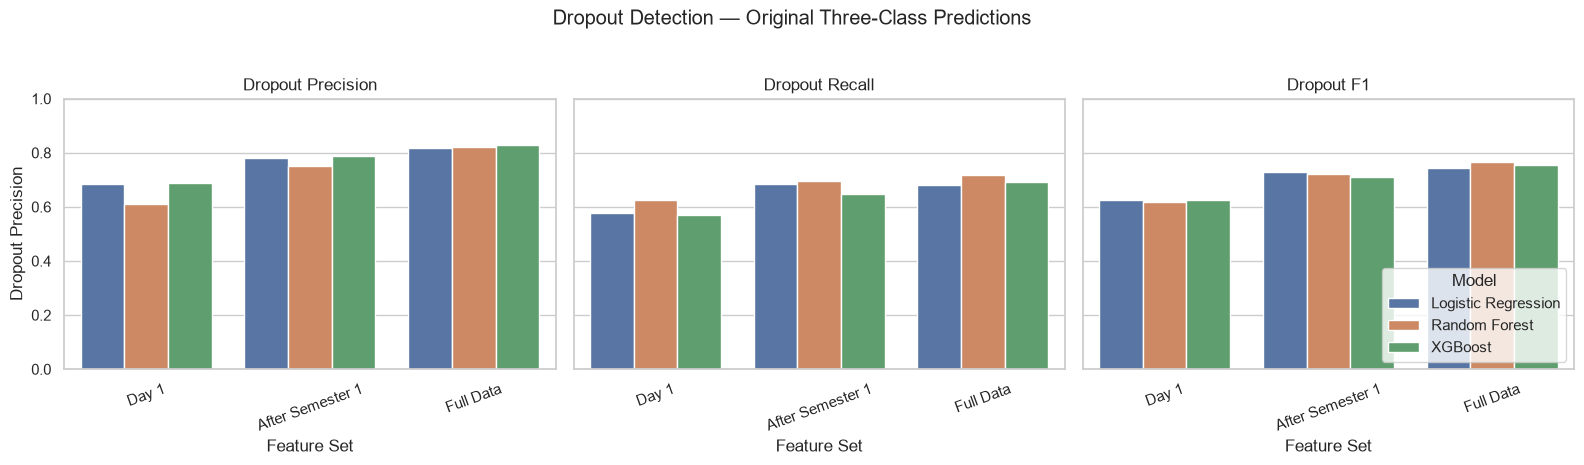

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, metric in zip(axes, ["Dropout Precision", "Dropout Recall", "Dropout F1"]):
    sns.barplot(data=metrics, x="Feature Set", y=metric, hue="Model", ax=ax, order=STAGES)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
    if ax is not axes[2]:
        ax.get_legend().remove()
axes[2].legend(loc="lower right", title="Model")
fig.suptitle("Dropout Detection — Original Three-Class Predictions", y=1.03)
plt.tight_layout()
plt.show()

Dropout detection improves substantially once Semester-1 academic information becomes available. Under the original multiclass prediction rule, Random Forest achieves the highest Dropout recall across all three feature sets, increasing from 62.7% at Day 1 to 69.7% after Semester 1 and 71.8% with Full Data. Logistic Regression and XGBoost show similar improvements after Semester 1.

However, higher recall sometimes comes at the cost of lower precision. For example, at Day 1, Random Forest identifies more actual Dropout students than Logistic Regression but also incorrectly flags more non-Dropout students. The relatively small improvements from After Semester 1 to Full Data suggest that much of the useful academic information for dropout detection is already available by the end of the first semester.

## 10.3 What happens to missed Dropout students?

The bars below use **actual Dropout students only**: each bar sums to 100%. Compare the two errors separately, since predicting a dropout as Graduate may tell a different story than predicting them as Enrolled.

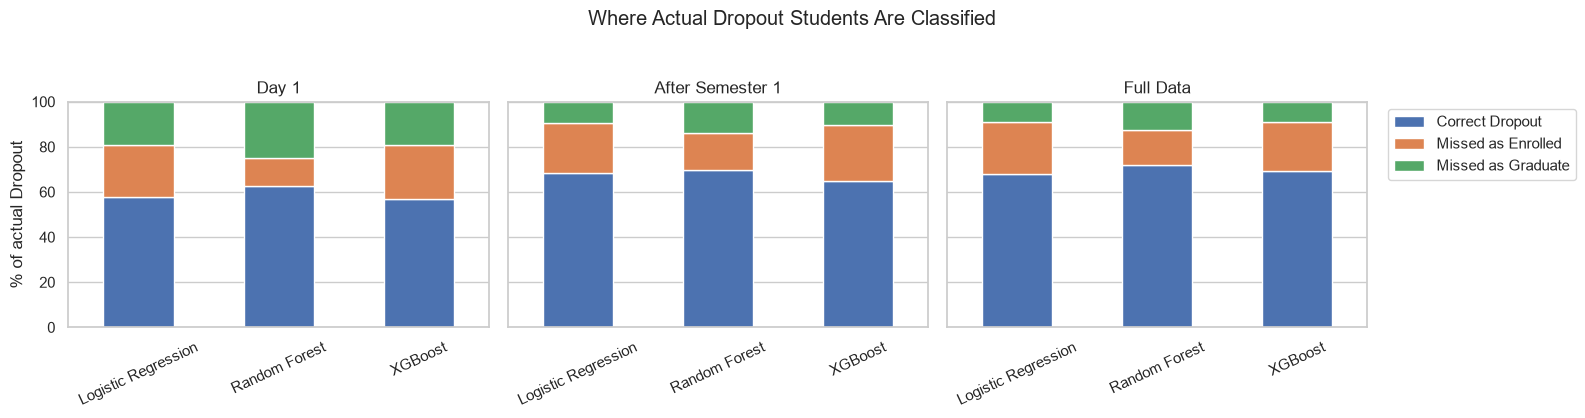

In [5]:
actual_dropout_n = int(y_test_raw.eq("Dropout").sum())
missed_plot = missed_table.set_index(["Feature Set", "Model"])[
    ["Correct Dropout", "Missed as Enrolled", "Missed as Graduate"]
].div(actual_dropout_n).mul(100)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, stage in zip(axes, STAGES):
    missed_plot.loc[stage].reindex(MODEL_NAMES).plot(kind="bar", stacked=True, ax=ax,
                                                     legend=(stage == "Full Data"))
    ax.set_title(stage); ax.set_ylabel("% of actual Dropout"); ax.set_ylim(0, 100)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
    if stage == "Full Data":
        ax.legend(bbox_to_anchor=(1.03, 1), loc="upper left")
plt.suptitle("Where Actual Dropout Students Are Classified", y=1.04)
plt.tight_layout(); plt.show()

The models differ in how they misclassify actual Dropout students. At Day 1, Logistic Regression and XGBoost incorrectly classify slightly more Dropout students as Enrolled than as Graduate, while Random Forest shows the opposite pattern. After Semester 1, all three models miss fewer Dropout students overall, although confusion with Enrolled remains substantial.

For example, after Semester 1, XGBoost misclassifies 71 actual Dropout students as Enrolled and 29 as Graduate. These findings suggest that distinguishing Dropout from Enrolled remains an important challenge for early-warning models, consistent with the overlapping student profiles identified in Notebook 09.

## 10.4 Select risk thresholds using the **training set only**

The operational question is binary: **flag for outreach** if `P(Dropout) >= t`; otherwise, do not flag. This is deliberately different from the original *three-class* argmax rule. We tune `t` using stratified **out-of-fold training predictions**, and then evaluate it **once** on the untouched holdout. We never choose a threshold by looking at test results.

The illustrative selection rule is: **maximize training-CV Dropout recall subject to training-CV precision ≥ `MIN_PRECISION`**. If no threshold satisfies that requirement, use the one with the highest out-of-fold binary F1 instead. This is an example policy choice; in practice intervention capacity and relative costs should set the constraint.

*Note:* class balancing can affect probability calibration. Thresholds here are exploratory operating points rather than calibrated dropout risks.

In [6]:
def oof_dropout_proba(stage, model_name, n_splits=N_FOLDS):
    cols = feature_sets[stage]
    Xtr = df.loc[train_idx, cols]
    ytr = y_train_raw
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    oof = pd.Series(index=Xtr.index, dtype=float)
    for fit_positions, validation_positions in cv.split(Xtr, ytr):
        X_fit, X_val = Xtr.iloc[fit_positions], Xtr.iloc[validation_positions]
        y_fit = ytr.iloc[fit_positions]
        _, _, proba = train_predict(model_name, cols, X_fit, y_fit, X_val)
        oof.loc[X_val.index] = proba["Dropout"]
    assert oof.notna().all()
    return oof

def threshold_stats(y_true, scores, threshold):
    truth = np.asarray(y_true) == "Dropout"
    predicted = np.asarray(scores) >= threshold
    tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[False, True]).ravel()
    return {"Precision": precision_score(truth, predicted, zero_division=0),
            "Recall": recall_score(truth, predicted, zero_division=0),
            "F1": f1_score(truth, predicted, zero_division=0),
            "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
            "Flagged": int(predicted.sum())}

def choose_threshold(y_train, oof_scores, threshold_grid=THRESHOLDS,
                     min_precision=MIN_PRECISION):
    table = pd.DataFrame([{"Threshold": t, **threshold_stats(y_train, oof_scores, t)}
                          for t in threshold_grid])
    feasible = table.loc[table["Precision"] >= min_precision]
    if not feasible.empty:
        # Among equal recalls, prefer higher precision; then higher threshold.
        selection = feasible.sort_values(
            ["Recall", "Precision", "Threshold"], ascending=[False, False, False]
        ).iloc[0]
        reason = f"Max CV recall with CV precision >= {min_precision:.0%}"
    else:
        selection = table.sort_values(
            ["F1", "Precision", "Threshold"], ascending=[False, False, False]
        ).iloc[0]
        reason = "No precision-feasible threshold; highest CV F1 fallback"
    return float(selection["Threshold"]), reason, table

selected_thresholds = {}
cv_curves = {}
for stage in EARLY_STAGES:
    for model in MODEL_NAMES:
        print(f"Training-only OOF threshold selection: {stage} | {model}")
        oof = oof_dropout_proba(stage, model)
        t, reason, grid = choose_threshold(y_train_raw, oof)
        selected_thresholds[(stage, model)] = {"Threshold": t, "Reason": reason,
                                               "CV metrics": threshold_stats(y_train_raw, oof, t)}
        cv_curves[(stage, model)] = grid

threshold_choices = pd.DataFrame([
    {"Feature Set": stage, "Model": model, "Chosen threshold": val["Threshold"],
     "Selection rule": val["Reason"],
     "OOF precision": val["CV metrics"]["Precision"],
     "OOF recall": val["CV metrics"]["Recall"]}
    for (stage, model), val in selected_thresholds.items()
])
display(threshold_choices.round(3))

Training-only OOF threshold selection: Day 1 | Logistic Regression
Training-only OOF threshold selection: Day 1 | Random Forest
Training-only OOF threshold selection: Day 1 | XGBoost
Training-only OOF threshold selection: After Semester 1 | Logistic Regression
Training-only OOF threshold selection: After Semester 1 | Random Forest
Training-only OOF threshold selection: After Semester 1 | XGBoost


,Feature Set,Model,Chosen threshold,Selection rule,OOF precision,OOF recall
0,Day 1,Logistic Regression,0.225,Max CV recall with CV precision >= 50%,0.508,0.790
1,Day 1,Random Forest,0.275,Max CV recall with CV precision >= 50%,0.513,0.799
2,Day 1,XGBoost,0.225,Max CV recall with CV precision >= 50%,0.509,0.808
3,After Semester 1,Logistic Regression,0.100,Max CV recall with CV precision >= 50%,0.515,0.915
4,After Semester 1,Random Forest,0.200,Max CV recall with CV precision >= 50%,0.529,0.909
5,After Semester 1,XGBoost,0.125,Max CV recall with CV precision >= 50%,0.520,0.912


The training-only cross-validation analysis selects relatively low dropout probability thresholds for all three models. The chosen thresholds range from 0.225 to 0.275 at Day 1 and from 0.100 to 0.200 after Semester 1. These thresholds reflect the objective of identifying as many potential Dropout students as possible while maintaining at least 50% precision on the out-of-fold training predictions.

Compared with the original three-class prediction rule, this approach prioritizes detecting students who may need intervention rather than assigning every student to one of the three outcomes. Importantly, the thresholds are selected without using holdout performance, reducing the risk of overfitting the decision rule to the test data.

## 10.5 Apply the selected thresholds to the unchanged holdout

Compare the tuned *binary outreach rule* with the model's original *three-class argmax Dropout flag*. Both use the same fitted model and holdout probabilities. **Do not compare the thresholded binary F1 with multiclass macro-F1 as if they were the same metric.**

In [7]:
comparison = []
for stage in EARLY_STAGES:
    for model in MODEL_NAMES:
        proba = fitted[(stage, model)]["proba"]["Dropout"]
        pred = fitted[(stage, model)]["pred"]
        t = selected_thresholds[(stage, model)]["Threshold"]
        base = threshold_stats(y_test_raw, pred.eq("Dropout").astype(float), 0.5)
        adjusted = threshold_stats(y_test_raw, proba, t)
        for name, values, threshold in [
            ("Original multiclass argmax", base, np.nan),
            ("CV-selected risk flag", adjusted, t)
        ]:
            comparison.append({"Feature Set": stage, "Model": model,
                               "Rule": name, "Threshold": threshold, **values})

risk_results = pd.DataFrame(comparison)
display(risk_results.round(3))

# Quantify benefit and alert burden relative to the original model.
pivot = risk_results.pivot(index=["Feature Set", "Model"], columns="Rule",
                           values=["Recall", "Precision", "FN", "FP", "Flagged"])
change_rows = []
for stage in EARLY_STAGES:
    for model in MODEL_NAMES:
        row = pivot.loc[(stage, model)]
        change_rows.append({"Feature Set": stage, "Model": model,
            "Fewer missed dropouts": int(row[("FN", "Original multiclass argmax")] - row[("FN", "CV-selected risk flag")]),
            "Additional false alarms": int(row[("FP", "CV-selected risk flag")] - row[("FP", "Original multiclass argmax")]),
            "Change in flagged students": int(row[("Flagged", "CV-selected risk flag")] - row[("Flagged", "Original multiclass argmax")]),
        })
changes = pd.DataFrame(change_rows)
display(changes)

# Sanity check all confusion-matrix cells.
assert (risk_results[["TP", "FN"]].sum(axis=1) == int(y_test_raw.eq("Dropout").sum())).all()
assert (risk_results[["TN", "FP"]].sum(axis=1) == int(y_test_raw.ne("Dropout").sum())).all()

,Feature Set,Model,Rule,Threshold,Precision,Recall,F1,TP,FN,FP,TN,Flagged
0,Day 1,Logistic Regression,Original multiclass argmax,NaN,0.686,0.577,0.627,164,120,75,526,239
1,Day 1,Logistic Regression,CV-selected risk flag,0.225,0.504,0.810,0.622,230,54,226,375,456
2,Day 1,Random Forest,Original multiclass argmax,NaN,0.610,0.627,0.618,178,106,114,487,292
3,Day 1,Random Forest,CV-selected risk flag,0.275,0.509,0.782,0.617,222,62,214,387,436
4,Day 1,XGBoost,Original multiclass argmax,NaN,0.689,0.570,0.624,162,122,73,528,235
5,Day 1,XGBoost,CV-selected risk flag,0.225,0.497,0.813,0.617,231,53,234,367,465
6,After Semester 1,Logistic Regression,Original multiclass argmax,NaN,0.782,0.683,0.729,194,90,54,547,248
7,After Semester 1,Logistic Regression,CV-selected risk flag,0.100,0.514,0.937,0.663,266,18,252,349,518
8,After Semester 1,Random Forest,Original multiclass argmax,NaN,0.750,0.697,0.723,198,86,66,535,264
9,After Semester 1,Random Forest,CV-selected risk flag,0.200,0.544,0.923,0.684,262,22,220,381,482


,Feature Set,Model,Fewer missed dropouts,Additional false alarms,Change in flagged students
0,Day 1,Logistic Regression,66,151,217
1,Day 1,Random Forest,44,100,144
2,Day 1,XGBoost,69,161,230
3,After Semester 1,Logistic Regression,72,198,270
4,After Semester 1,Random Forest,64,154,218
5,After Semester 1,XGBoost,79,193,272


In [8]:

# Percentage of holdout students flagged for intervention
risk_results["Flagged (%)"] = (
    100 * risk_results["Flagged"] / len(y_test_raw)
)

display(
    risk_results[
        [
            "Feature Set", "Model", "Rule",
            "Precision", "Recall", "FN", "FP",
            "Flagged", "Flagged (%)"
        ]
    ].round(2)
)


,Feature Set,Model,Rule,Precision,Recall,FN,FP,Flagged,Flagged (%)
0,Day 1,Logistic Regression,Original multiclass argmax,0.69,0.58,120,75,239,27.01
1,Day 1,Logistic Regression,CV-selected risk flag,0.50,0.81,54,226,456,51.53
2,Day 1,Random Forest,Original multiclass argmax,0.61,0.63,106,114,292,32.99
3,Day 1,Random Forest,CV-selected risk flag,0.51,0.78,62,214,436,49.27
4,Day 1,XGBoost,Original multiclass argmax,0.69,0.57,122,73,235,26.55
5,Day 1,XGBoost,CV-selected risk flag,0.50,0.81,53,234,465,52.54
6,After Semester 1,Logistic Regression,Original multiclass argmax,0.78,0.68,90,54,248,28.02
7,After Semester 1,Logistic Regression,CV-selected risk flag,0.51,0.94,18,252,518,58.53
8,After Semester 1,Random Forest,Original multiclass argmax,0.75,0.70,86,66,264,29.83
9,After Semester 1,Random Forest,CV-selected risk flag,0.54,0.92,22,220,482,54.46


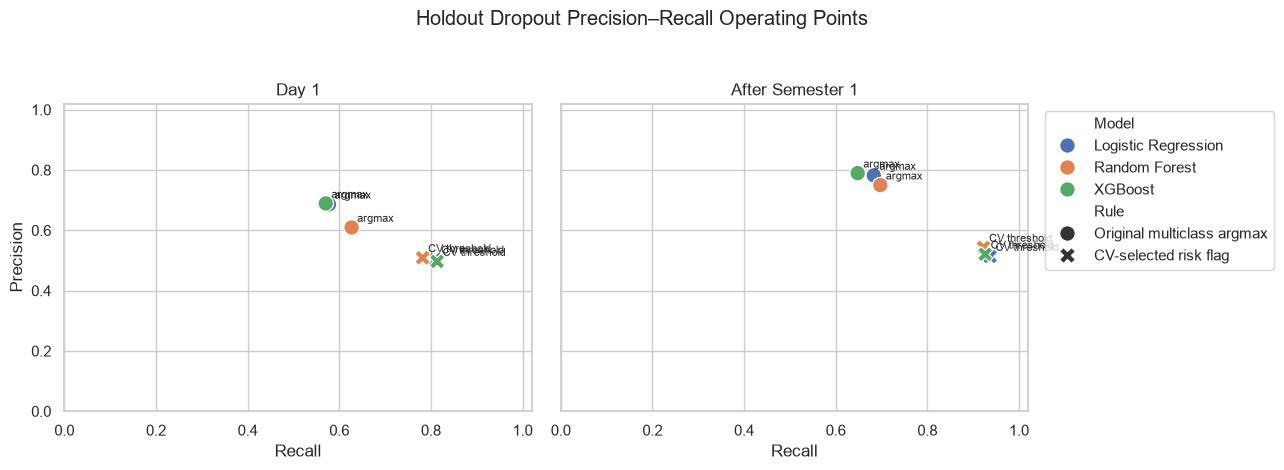

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, stage in zip(axes, EARLY_STAGES):
    subset = risk_results[risk_results["Feature Set"] == stage]
    sns.scatterplot(data=subset, x="Recall", y="Precision", hue="Model", style="Rule",
                    s=125, ax=ax)
    for _, row in subset.iterrows():
        ax.annotate("CV threshold" if row["Rule"] == "CV-selected risk flag" else "argmax",
                    (row["Recall"], row["Precision"]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8)
    ax.set_title(stage); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
axes[0].get_legend().remove()
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.suptitle("Holdout Dropout Precision–Recall Operating Points", y=1.04)
plt.tight_layout(); plt.show()

Adjusting the dropout probability threshold substantially improves recall for all three models, but also increases the number of false-positive risk flags. At Day 1, the adjusted rules identify approximately 78–81% of actual Dropout students, compared with 57–63% under the original multiclass prediction rule. After Semester 1, recall increases to approximately 92–94%.

For example, after Semester 1, Random Forest recall increases from 69.7% to 92.3%, reducing the number of missed Dropout students from 86 to 22. However, the number of false alarms increases from 66 to 220, and the total number of students flagged increases from 264 to 482 out of 885.

These results illustrate the tradeoff between identifying more at-risk students and placing a greater burden on intervention resources. Lower thresholds can reduce missed dropout cases, but the resulting decrease in precision means that a larger proportion of flagged students will not belong to the observed Dropout class. Therefore, selecting an appropriate threshold depends on how a university prioritizes missed intervention opportunities relative to unnecessary outreach.

## 10.6 Precision–recall curves (descriptive; not for selecting thresholds)

These holdout curves show the continuum of possible binary flagging rules. **Average precision** is a threshold-free summary of ranking performance, but it is *not* the same as precision at the selected threshold. The marked point was selected on training folds, never from these curves.

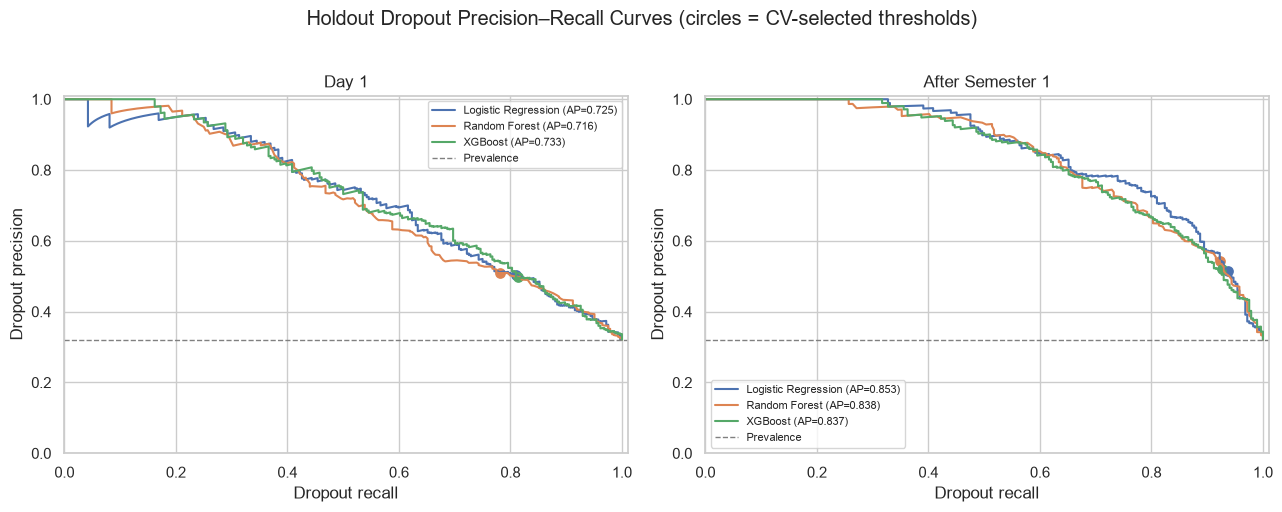

,Feature Set,Model,Average Precision
0,Day 1,Logistic Regression,0.725
1,Day 1,Random Forest,0.716
2,Day 1,XGBoost,0.733
3,After Semester 1,Logistic Regression,0.853
4,After Semester 1,Random Forest,0.838
5,After Semester 1,XGBoost,0.837


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
curve_rows = []
truth = y_test_raw.eq("Dropout").astype(int)
for ax, stage in zip(axes, EARLY_STAGES):
    for model in MODEL_NAMES:
        scores = fitted[(stage, model)]["proba"]["Dropout"]
        precision, recall, _ = precision_recall_curve(truth, scores)
        ap = average_precision_score(truth, scores)
        curve_rows.append({"Feature Set": stage, "Model": model, "Average Precision": ap})
        ax.plot(recall, precision, label=f"{model} (AP={ap:.3f})")
        t = selected_thresholds[(stage, model)]["Threshold"]
        chosen = threshold_stats(y_test_raw, scores, t)
        ax.scatter(chosen["Recall"], chosen["Precision"], s=45, marker="o")
    ax.axhline(truth.mean(), linestyle="--", linewidth=1, color="gray", label="Prevalence")
    ax.set_title(stage); ax.set_xlabel("Dropout recall"); ax.set_ylabel("Dropout precision")
    ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.01)
    ax.legend(fontsize=8)
plt.suptitle("Holdout Dropout Precision–Recall Curves (circles = CV-selected thresholds)", y=1.02)
plt.tight_layout(); plt.show()
display(pd.DataFrame(curve_rows).round(3))

The precision–recall curves show that all three models become better at distinguishing Dropout students from non-Dropout students once Semester-1 information is available. Average Precision increases from approximately 0.72–0.73 at Day 1 to 0.84–0.85 after Semester 1.

XGBoost achieves the highest Average Precision at Day 1 (0.733), while Logistic Regression performs best after Semester 1 (0.853), although the differences between models are relatively small. Interestingly, Random Forest has the highest Dropout recall under the original multiclass decision rule, but not the highest Average Precision. This highlights the difference between evaluating performance at a particular decision rule and evaluating how well a model ranks students across possible thresholds.

Overall, Semester-1 academic information improves not only classification at the original decision rule, but also the ability to prioritize students by predicted dropout risk.

## 10.7 Key Findings and Conclusion

The dropout-focused evaluation shows that Semester-1 academic information substantially improves the ability to identify students who ultimately drop out. Under the original multiclass decision rule, Random Forest achieves the highest Dropout recall across all three feature sets, increasing from 62.7% at Day 1 to 69.7% after Semester 1 and 71.8% with Full Data. However, differences in precision and Average Precision suggest that no single model performs best under every evaluation criterion.

The analysis of false negatives reveals that actual Dropout students are frequently misclassified as either Enrolled or Graduate. Even after Semester 1, confusion with Enrolled remains substantial, consistent with the overlapping academic profiles identified in Notebook 09.

Selecting dropout risk thresholds using training-only cross-validation substantially improves recall. At Day 1, the adjusted rules detect approximately 78–81% of actual Dropout students, while after Semester 1, recall increases to approximately 92–94%. For example, the After Semester 1 Random Forest model reduces the number of missed Dropout students from 86 to 22.

However, these improvements come at a considerable cost in false alarms. For the same Random Forest model, false positives increase from 66 to 220, and the number of students flagged increases from 264 to 482 out of 885. This illustrates that maximizing dropout detection is not necessarily equivalent to choosing the most practical intervention strategy.

The precision–recall analysis further demonstrates the importance of Semester-1 academic information. Average Precision increases across all three models, suggesting that later academic information improves their ability to rank students by dropout risk, regardless of the specific decision threshold.

Overall, these findings suggest that early dropout identification is feasible but requires balancing detection performance against intervention capacity. Lowering the classification threshold can identify substantially more students at risk, but universities would need to determine an acceptable level of unnecessary outreach before applying such a system.

### Limitations

This analysis uses one stratified holdout split, and threshold selection is based on three-fold cross-validation within the training data. The 50% precision constraint is illustrative rather than an established institutional policy, and meeting it during training does not guarantee the same precision on new students. Additionally, class balancing may affect probability calibration, so the estimated probabilities should not automatically be interpreted as actual dropout risks. Finally, the dataset does not evaluate the effects of interventions, meaning that identifying additional Dropout students does not necessarily demonstrate that their outcomes could have been changed.